# Unsupervised experiment: two occupied-room recordings, 2026-10-25

The user identifies **both** `csi_20261025_200543.csv` and
`csi_20261025_210326.csv` as occupied-room recordings. The earlier description
of the later file as mostly empty was corrected. Counts, activity, placement,
and interval-level occupancy labels are unknown. No occupancy labels are
fabricated, and no occupied-versus-empty accuracy can be calculated.

This notebook reuses the preprocessing, candidate pipeline array, and evaluation
helpers from `csi_modeling.ipynb`. All configuration remains visible and editable.
Fit on the first 60% of **each** recording; compare on the next 20%, with purges.
The final 20% remains locked. Filenames, recording context, and timestamps are
metadata, not model inputs. No labels participate in fitting or model selection.

Report cluster separation, held-out density, seed stability, state profiles, and
the mix of states in each occupied recording. Differences between recordings
can reflect activity, environment, or radio conditions and do not establish
human-presence discrimination or room fullness.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA

relative = Path('drafts/modeling_and_analysis')
search = [candidate for parent in (Path.cwd(), *Path.cwd().parents)
          for candidate in (parent, parent/'modeling_and_analysis', parent/relative)]
EXAMPLE_DIR = next((p for p in search if (p/'csi_dataset.py').is_file()), None)
if EXAMPLE_DIR is None:
    raise FileNotFoundError('Run the notebook from modeling_and_analysis or its repository root.')
if str(EXAMPLE_DIR) not in sys.path:
    sys.path.insert(0, str(EXAMPLE_DIR))
import importlib
import csi_dataset
import csi_models
importlib.reload(csi_dataset)
importlib.reload(csi_models)
from csi_dataset import (MOTION_FEATURES, PHASE_FEATURES, SLOW_FEATURES,
    load_dataset, load_annotations, partition_dataset, select_features, quality_mask)
from csi_models import (compare_unsupervised, run_change_models, compare_classifiers,
    classification_metrics, save_bundle, predict_bundle)
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
print('Kernel:', sys.executable)
print('Example:', EXAMPLE_DIR)


Kernel: E:\Espressif\tools\python\v6.1\venv\Scripts\python.exe
Example: E:\IOT\esp-csi\drafts\modeling_and_analysis


In [2]:
# Edit these parameters and feature lists before running experiments.
EXPERIMENT_DIR = EXAMPLE_DIR / 'experiments' / 'occupied_pair_20261025'
MANIFEST_PATH = EXPERIMENT_DIR / 'manifest.csv'
LABELS_PATH = None
EVENTS_PATH = None
FEATURE_COLUMNS = list(MOTION_FEATURES)
# Optional ablations: FEATURE_COLUMNS += PHASE_FEATURES or SLOW_FEATURES
FAST_PARAMETERS = dict(window_seconds=5.0, hop_seconds=1.0, min_packets=12, max_gap_seconds=2.0)
SLOW_PARAMETERS = dict(window_seconds=30.0, hop_seconds=5.0, min_packets=12, max_gap_seconds=2.0)
GROUP_COLUMN = 'session_id'  # or day/placement_id after filling the manifest
USE_SLOW = any(name in SLOW_FEATURES for name in FEATURE_COLUMNS)
PURGE_SECONDS = SLOW_PARAMETERS['window_seconds'] if USE_SLOW else FAST_PARAMETERS['window_seconds']
RUN_ID = pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')
REPORT_DIR = EXPERIMENT_DIR / 'runs' / RUN_ID
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = REPORT_DIR / 'models'
SAVE_MODELS = True

dataset = load_dataset(MANIFEST_PATH, LABELS_PATH, FAST_PARAMETERS, SLOW_PARAMETERS,
                       use_slow_features=USE_SLOW)
events = load_annotations(EVENTS_PATH, kind='events')
display(dataset.groupby(['session_id', 'split']).agg(
    windows=('quality_ok', 'size'), quality_windows=('quality_ok', 'sum'),
    labeled_windows=('presence', 'count')))
print('Predictive inputs:', FEATURE_COLUMNS)
print('Timestamps, metadata, labels, packet gaps/rates, and quality flags are excluded from X.')
print('Reports:', REPORT_DIR)


,,windows,quality_windows,labeled_windows
session_id,split,,,
csi_20261025_200543,unassigned,594,127,0
csi_20261025_210326,unassigned,595,217,0


Predictive inputs: ['amplitude_mean', 'amplitude_std_median', 'amplitude_mad_median', 'amplitude_cv_median', 'amplitude_step_median', 'amplitude_change_rate_median', 'normalized_std_median', 'normalized_step_median', 'subcarrier_abs_correlation', 'pca1_variance_fraction']
Timestamps, metadata, labels, packet gaps/rates, and quality flags are excluded from X.
Reports: E:\IOT\esp-csi\drafts\modeling_and_analysis\experiments\occupied_pair_20261025\runs\20261026T012619746575Z


## Prespecified temporal split and sampling coverage

Use the original 5-second windows, 1-second steps, minimum 12 packets, and maximum
2-second gap. No thresholds are relaxed to improve sample counts. A separate
30-second feature table is constructed, but the default models use only the ten
motion/amplitude features. Quality-failing windows are excluded from fitting
and retain unknown state assignments. Evaluation is conditional on accepted
windows; the coverage table shows how much of each recording was rejected.

The loader accepts signed timestamp representations from the firmware and
unwraps the 32-bit counter before calculating elapsed seconds. No negative-counter
packets are discarded solely because of the printed sign.


In [3]:
# A temporal development split INSIDE each occupied recording, not independent-session testing.
TRAIN_FRACTION = 0.60
VALIDATION_END_FRACTION = 0.80
dataset['split'] = 'purged'
for session, group in dataset.groupby('session_id'):
    end = float(group.window_end_s.max())
    training_end, validation_end = end*TRAIN_FRACTION, end*VALIDATION_END_FRACTION
    indices = group.index[group.window_end_s <= training_end]
    dataset.loc[indices, 'split'] = 'train'
    indices = group.index[(group.feature_start_s >= training_end+PURGE_SECONDS) &
                          (group.window_end_s <= validation_end)]
    dataset.loc[indices, 'split'] = 'validation'
    indices = group.index[group.feature_start_s >= validation_end+PURGE_SECONDS]
    dataset.loc[indices, 'split'] = 'test'
train = dataset[dataset.split=='train'].copy()
validation = dataset[dataset.split=='validation'].copy()
final_test = dataset[dataset.split=='test'].copy()
from csi_dataset import assert_disjoint
for left, right in [(train,validation),(train,final_test),(validation,final_test)]:
    assert_disjoint(left,right)  # same session IDs are intentional; raw intervals cannot overlap
split_mode = 'Exploratory chronological split within TWO occupied recordings; not independent-session evaluation'
print(split_mode)
coverage = dataset.groupby(['session_id','split']).agg(
    windows=('quality_ok','size'), passing_windows=('quality_ok','sum'))
coverage['quality_coverage'] = coverage.passing_windows/coverage.windows
display(coverage)
dataset.to_csv(REPORT_DIR/'features_and_splits.csv',index=False)
coverage.to_csv(REPORT_DIR/'sampling_coverage.csv')


Exploratory chronological split within TWO occupied recordings; not independent-session evaluation


windows  passing_windows  quality_coverage
session_id          split                                                 
csi_20261025_200543 purged           20                4          0.200000
                    test            110               21          0.190909
                    train           354               81          0.228814
                    validation      110               21          0.190909
csi_20261025_210326 purged           20               12          0.600000
                    test            110               33          0.300000
                    train           355              142          0.400000
                    validation      110               30          0.272727

## Exposed scikit-learn pipeline array

Six GMMs (1/2/3 components, diagonal or tied covariance), KMeans, and HDBSCAN.
Scaling and imputation fit only on accepted training windows. BIC and likelihood
are comparable here because GMMs use the same transformed feature representation.
HDBSCAN lacks out-of-sample predict in sklearn, so its validation scores remain
unavailable. Silhouette and seed stability are descriptive, not occupancy accuracy.


In [4]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, HDBSCAN

# Expand this list freely. Every candidate is cloned before fitting.
# These candidates deliberately use the same representation for fair GMM BIC comparisons.
UNSUPERVISED_PIPELINES = [
    {'name': f'gmm_{components}_{covariance}', 'representation': 'scaled_motion',
     'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()),
        ('scaler', StandardScaler()),
        # Insert ('pca', PCA(n_components=0.95)) here and change representation to compare a PCA family.
        ('model', GaussianMixture(n_components=components, covariance_type=covariance,
                                  reg_covar=1e-4, n_init=5, random_state=42)),
     ])}
    for covariance in ['diag', 'tied'] for components in [1, 2, 3]
] + [
    {'name': 'kmeans_2', 'representation': 'scaled_motion', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
        ('model', KMeans(n_clusters=2, n_init=10, random_state=42)),
    ])},
    {'name': 'hdbscan', 'representation': 'scaled_motion', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
        ('model', HDBSCAN(min_cluster_size=8, min_samples=4, copy=True)),
    ])},
]
# Add custom sklearn-compatible scoring functions. Context contains the fitted
# pipeline, transformed X_train, train_labels, and available validation outputs.
EXTRA_UNSUPERVISED_METRICS = {
    # 'davies_bouldin': lambda c: davies_bouldin_score(c['X_train'], c['train_labels']),
}
STABILITY_SEEDS = [7, 19, 41]
display(pd.DataFrame([{'name': p['name'], 'pipeline': str(p['pipeline'])} for p in UNSUPERVISED_PIPELINES]))


,name,pipeline
0,gmm_1_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
1,gmm_2_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
2,gmm_3_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
3,gmm_1_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
4,gmm_2_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
5,gmm_3_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
6,kmeans_2,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
7,hdbscan,"Pipeline(steps=[('imputer', SimpleImputer(stra..."


In [5]:
unsupervised_metrics, unsupervised_results = compare_unsupervised(
    UNSUPERVISED_PIPELINES, train, validation, FEATURE_COLUMNS,
    stability_seeds=STABILITY_SEEDS, extra_metrics=EXTRA_UNSUPERVISED_METRICS)
display(unsupervised_metrics)
print('Evaluation:', split_mode)
unsupervised_metrics.to_csv(REPORT_DIR/'unsupervised_metrics.csv', index=False)


,model,status,train_rows,validation_rows,representation,clusters,train_noise_fraction,train_silhouette,transformed_dimensions,train_bic,validation_silhouette,validation_log_likelihood,seed_stability_ARI,validation_note
0,gmm_1_diag,ok,223,51,scaled_motion,1,0.000000,NaN,10,6436.609305,NaN,-14.146585,1.000000,NaN
1,gmm_2_diag,ok,223,51,scaled_motion,2,0.000000,0.315130,10,5099.272447,0.405900,-10.232115,1.000000,NaN
2,gmm_3_diag,ok,223,51,scaled_motion,3,0.000000,0.331401,10,4529.366652,0.419593,-9.559534,0.822917,NaN
3,gmm_1_tied,ok,223,51,scaled_motion,1,0.000000,NaN,10,3604.746097,NaN,-8.325814,1.000000,NaN
4,gmm_2_tied,ok,223,51,scaled_motion,2,0.000000,0.317717,10,3373.784742,0.405900,-7.687574,1.000000,NaN
5,gmm_3_tied,ok,223,51,scaled_motion,3,0.000000,0.349250,10,3127.068145,0.405900,-8.201911,1.000000,NaN
6,kmeans_2,ok,223,51,scaled_motion,2,0.000000,0.323496,10,NaN,0.405900,NaN,1.000000,NaN
7,hdbscan,ok,223,51,scaled_motion,3,0.345291,0.498529,10,NaN,NaN,NaN,NaN,Estimator has no out-of-sample predict (e.g. s...


Evaluation: Exploratory chronological split within TWO occupied recordings; not independent-session evaluation


In [6]:
# Select one illustrative GMM using validation density only, never recording context.
eligible = unsupervised_metrics[
    unsupervised_metrics.status.eq('ok') &
    unsupervised_metrics.model.str.startswith('gmm_')].dropna(subset=['validation_log_likelihood'])
if eligible.empty:
    raise ValueError('No GMM successfully fitted; inspect candidate results.')
SELECTED_MODEL = eligible.sort_values('validation_log_likelihood',ascending=False).iloc[0].model
print('Selected by highest mean validation log likelihood:',SELECTED_MODEL)
result = unsupervised_results[SELECTED_MODEL]
display(result['pipeline'])

state_tables = []
for name, output in unsupervised_results.items():
    frame = train.copy()
    frame['predicted_state'] = np.nan
    frame.loc[output['train_rows'].index,'predicted_state'] = output['train_labels']
    if 'validation_labels' in output:
        val = validation.copy()
        val['predicted_state'] = np.nan
        val.loc[output['validation_rows'].index,'predicted_state'] = output['validation_labels']
        frame = pd.concat([frame,val])
    frame['model'] = name
    state_tables.append(frame)
predictions = pd.concat(state_tables,ignore_index=True)
predictions.to_csv(REPORT_DIR/'development_state_assignments.csv',index=False)
composition = predictions.dropna(subset=['predicted_state']).groupby(
    ['model','split','session_id','predicted_state']).size().rename('windows').reset_index()
composition['fraction'] = composition.windows / composition.groupby(
    ['model','split','session_id']).windows.transform('sum')
composition.to_csv(REPORT_DIR/'recording_state_composition.csv',index=False)
display(composition[composition.model.eq(SELECTED_MODEL)])
print('No presence precision/recall/accuracy: both recordings have only coarse occupied context.')


Selected by highest mean validation log likelihood: gmm_2_tied


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['amplitude_mean','amplitude_std_median','amplitude_mad_median',..., 'normalized_step_median','subcarrier_abs_correlation', 'pca1_variance_fraction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 wh

,model,split,session_id,predicted_state,windows,fraction
13,gmm_2_tied,train,csi_20261025_200543,0.0,1,0.012346
14,gmm_2_tied,train,csi_20261025_200543,1.0,80,0.987654
15,gmm_2_tied,train,csi_20261025_210326,0.0,139,0.978873
16,gmm_2_tied,train,csi_20261025_210326,1.0,3,0.021127
17,gmm_2_tied,validation,csi_20261025_200543,1.0,21,1.000000
18,gmm_2_tied,validation,csi_20261025_210326,0.0,30,1.000000


No presence precision/recall/accuracy: both recordings have only coarse occupied context.


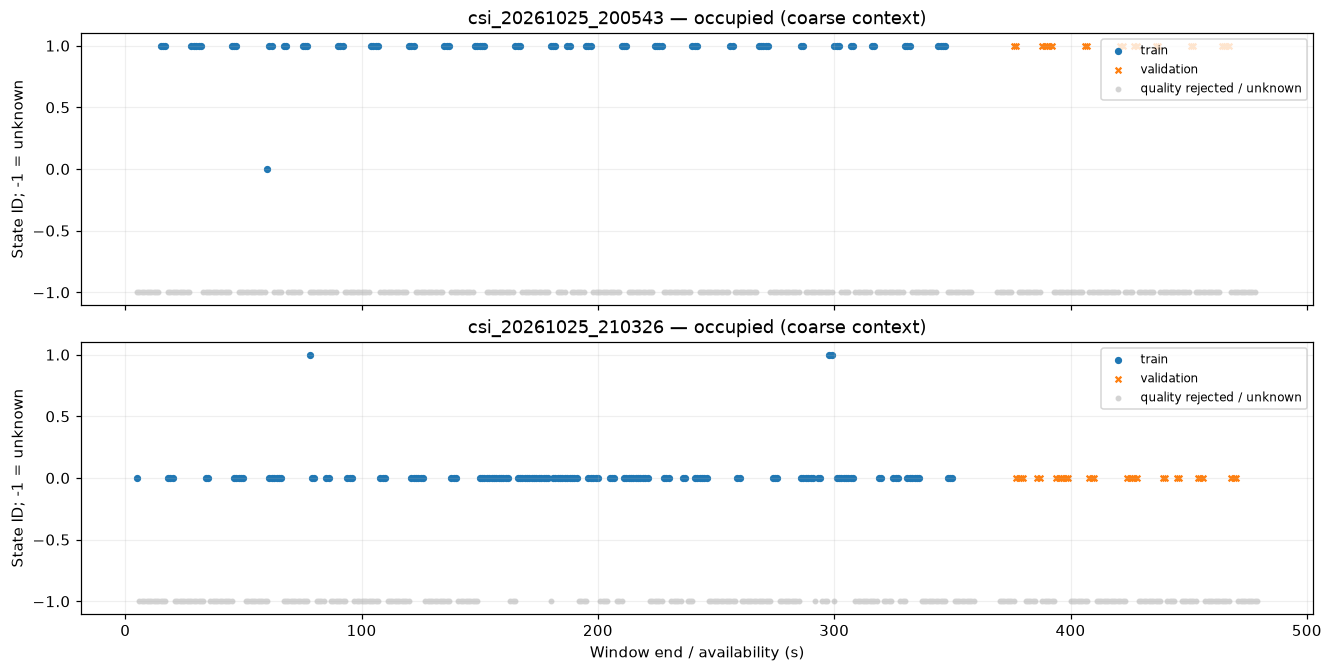

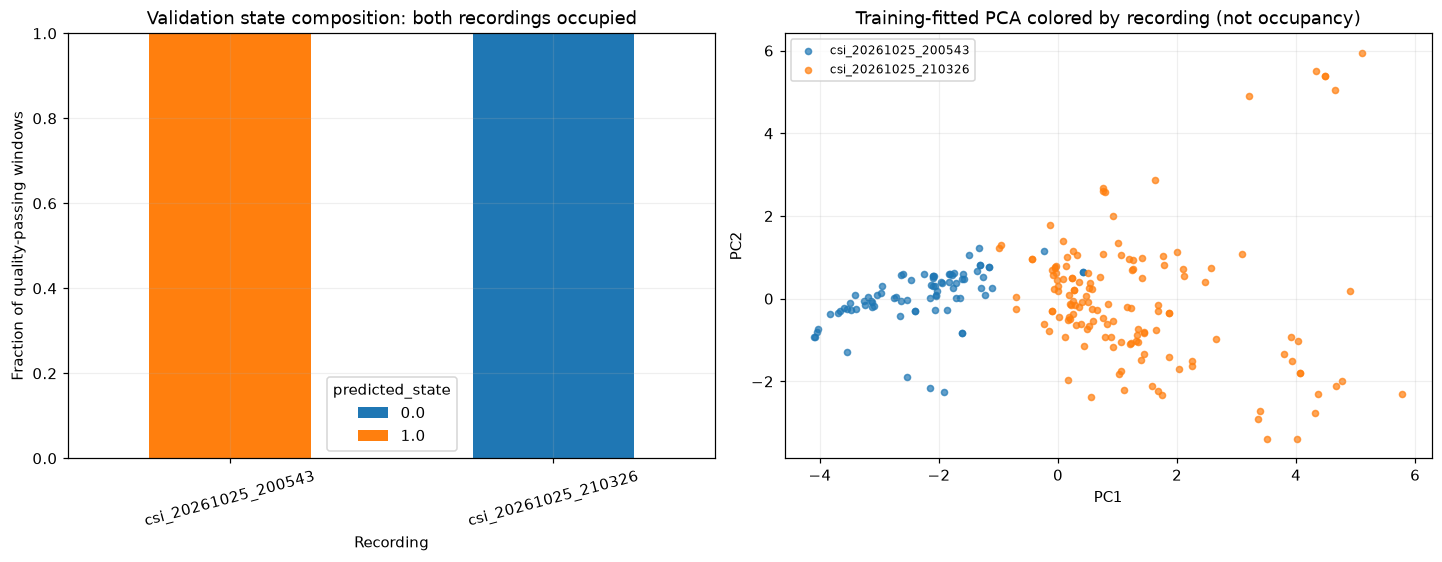

,amplitude_mean,amplitude_std_median,amplitude_mad_median,amplitude_cv_median,amplitude_step_median,amplitude_change_rate_median,normalized_std_median,normalized_step_median,subcarrier_abs_correlation,pca1_variance_fraction
state,,,,,,,,,,
0,16.614021,3.341609,1.286723,0.195350,1.543887,191.606517,0.021747,0.021209,0.242999,0.211884
1,20.626783,2.863022,0.572083,0.136282,0.807193,130.854477,0.017085,0.016901,0.199573,0.172086


In [7]:
selected = predictions[predictions.model.eq(SELECTED_MODEL)].copy()
sessions = sorted(selected.session_id.unique())
fig, axes = plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
for ax, session in zip(axes,sessions):
    group = selected[selected.session_id.eq(session)]
    for split, subset in group.groupby('split'):
        ax.scatter(subset.window_end_s, subset.predicted_state,s=14,
                   marker='o' if split=='train' else 'x',label=split)
    failed = group.predicted_state.isna()
    ax.scatter(group.loc[failed,'window_end_s'], np.full(failed.sum(),-1),
               s=8,color='lightgray',label='quality rejected / unknown')
    ax.set(title=f'{session} — occupied (coarse context)',ylabel='State ID; -1 = unknown')
    ax.legend(loc='upper right',fontsize=8)
axes[-1].set_xlabel('Window end / availability (s)')
fig.savefig(REPORT_DIR/'state_timelines.png',dpi=150)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
plot_rows = selected[selected.split.eq('validation')].dropna(subset=['predicted_state'])
table=pd.crosstab(plot_rows.session_id,plot_rows.predicted_state,normalize='index')
table.plot.bar(stacked=True,ax=axes[0],rot=15)
axes[0].set(title='Validation state composition: both recordings occupied',
            ylabel='Fraction of quality-passing windows',xlabel='Recording')
xy=result['train_projection']
train_rows=result['train_rows']
for session in sessions:
    mask=train_rows.session_id.eq(session).to_numpy()
    axes[1].scatter(xy[mask,0],xy[mask,1],s=16,label=session,alpha=.7)
axes[1].set(title='Training-fitted PCA colored by recording (not occupancy)',xlabel='PC1',ylabel='PC2')
axes[1].legend(fontsize=8)
fig.savefig(REPORT_DIR/'composition_and_projection.png',dpi=150)
plt.show()

profiles=result['train_rows'].copy()
profiles['state']=result['train_labels']
display(profiles.groupby('state')[FEATURE_COLUMNS].median())
profiles.groupby('state')[FEATURE_COLUMNS].median().to_csv(REPORT_DIR/'selected_state_profiles.csv')


In [8]:
provenance=dict(experiment='occupied_pair_20261025',
    recording_context='Both recordings identified by user as occupied; no interval labels',
    selection='Highest validation mean log likelihood among the exposed GMM candidates',
    split_mode=split_mode, fast_parameters=FAST_PARAMETERS,slow_parameters=SLOW_PARAMETERS,
    training_sessions=train.session_id.unique().tolist(),
    validation_sessions=validation.session_id.unique().tolist(),
    manifest=MANIFEST_PATH.read_text(encoding='utf-8'))
if SAVE_MODELS:
    save_bundle(MODEL_DIR/f'{SELECTED_MODEL}.joblib',result['pipeline'],FEATURE_COLUMNS,provenance)
summary=dict(selected_model=SELECTED_MODEL,
    data_quality=coverage.reset_index().to_dict(orient='records'),
    feature_columns=FEATURE_COLUMNS,
    interpretation='Exploratory signal-state clustering within two occupied recordings; not a presence classifier',
    final_test_evaluated=False)
(REPORT_DIR/'experiment_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Reports:',REPORT_DIR)
print('Final test remains locked. No occupied/empty accuracy or count is estimated.')


Reports: E:\IOT\esp-csi\drafts\modeling_and_analysis\experiments\occupied_pair_20261025\runs\20261026T012619746575Z
Final test remains locked. No occupied/empty accuracy or count is estimated.
